# Prompt 1 — Geolistrik Resistivitas: Identifikasi Akuifer

**Nama:** Abdussalam Said Al Mubarak  
**NIM:** H061241027

Notebook ini mendemonstrasikan alur analisis resistivitas untuk mengidentifikasi **zona yang berpotensi sebagai akuifer**. Karena data lapangan tidak disertakan, seluruh data dibuat sintetis. Model yang divisualisasikan adalah model ilustratif, **bukan hasil inversi data survei nyata**. Resistivitas rendah tidak otomatis berarti akuifer; lempung dapat bersifat konduktif tetapi berpermeabilitas rendah.

## 1. Tujuan dan alur
1. Membuat model resistivitas bawah permukaan sintetis.
2. Menampilkan penampang resistivitas dan profil vertikal.
3. Membuat tabel lapisan, kedalaman, ketebalan, dan interpretasi awal.
4. Menjelaskan keterbatasan identifikasi akuifer tanpa inversi dan data pembanding.

**Pemisahan penting:** data pengukuran lapangan → resistivitas semu → hasil inversi → interpretasi geologi. Notebook ini hanya mendemonstrasikan visualisasi model konseptual; tidak melakukan inversi data lapangan.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["image.cmap"] = "turbo"

## 2. Model resistivitas sintetis
Nilai berikut dipilih untuk contoh pembelajaran. Rentang resistivitas material tidak universal dan dapat saling tumpang tindih.

In [2]:
# Grid ilustratif
x = np.linspace(0, 100, 101)       # jarak horizontal (m)
z = np.linspace(0, 30, 61)         # kedalaman (m), positif ke bawah
X, Z = np.meshgrid(x, z)

# Model 3 lapisan sederhana: 0-3 m, 3-8 m, 8-20 m, lalu material lebih kompak
rho = np.zeros_like(X, dtype=float)
rho[Z < 3] = 90                    # tanah penutup
rho[(Z >= 3) & (Z < 8)] = 12       # lempung/lanau
rho[(Z >= 8) & (Z < 20)] = 35      # pasir/pasir kerikil jenuh air: potensial akuifer
rho[Z >= 20] = 180                 # material kompak/batuan dasar ilustratif

# Tambahkan variasi lateral kecil agar visualisasi tidak sepenuhnya seragam
rho *= (1 + 0.08*np.sin(X/13) * np.exp(-Z/20))

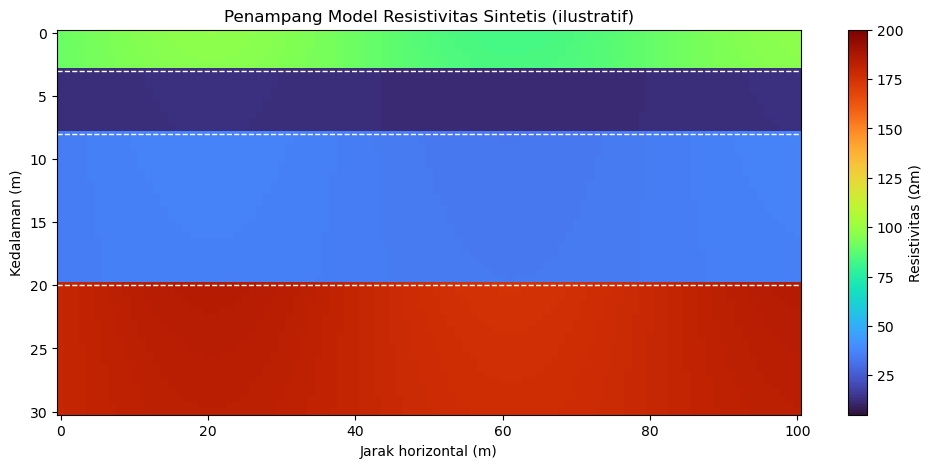

In [3]:
fig, ax = plt.subplots(figsize=(12, 5))
im = ax.pcolormesh(X, Z, rho, shading="auto", vmin=5, vmax=200)
ax.invert_yaxis()
ax.set_xlabel("Jarak horizontal (m)")
ax.set_ylabel("Kedalaman (m)")
ax.set_title("Penampang Model Resistivitas Sintetis (ilustratif)")
cb = fig.colorbar(im, ax=ax)
cb.set_label("Resistivitas (Ωm)")
ax.axhline(3, color="white", ls="--", lw=1)
ax.axhline(8, color="white", ls="--", lw=1)
ax.axhline(20, color="white", ls="--", lw=1)
plt.show()

## 3. Model lapisan bawah permukaan
Kedalaman batas pada tabel berikut berasal dari model sintetis yang didefinisikan di atas, bukan dari hasil pengukuran.

In [4]:
layers = pd.DataFrame([
    {"Lapisan": 1, "Kedalaman atas (m)": 0, "Kedalaman bawah (m)": 3,
     "Ketebalan (m)": 3, "Resistivitas contoh (Ωm)": 90,
     "Interpretasi awal": "Tanah penutup / material lapukan"},
    {"Lapisan": 2, "Kedalaman atas (m)": 3, "Kedalaman bawah (m)": 8,
     "Ketebalan (m)": 5, "Resistivitas contoh (Ωm)": 12,
     "Interpretasi awal": "Lempung atau lanau; mungkin berperan sebagai akuitar"},
    {"Lapisan": 3, "Kedalaman atas (m)": 8, "Kedalaman bawah (m)": 20,
     "Ketebalan (m)": 12, "Resistivitas contoh (Ωm)": 35,
     "Interpretasi awal": "Pasir/pasir kerikil jenuh air; zona potensial akuifer"},
    {"Lapisan": 4, "Kedalaman atas (m)": 20, "Kedalaman bawah (m)": 30,
     "Ketebalan (m)": 10, "Resistivitas contoh (Ωm)": 180,
     "Interpretasi awal": "Material lebih kompak; perlu konfirmasi geologi"},
])
display(layers)

,Lapisan,Kedalaman atas (m),Kedalaman bawah (m),Ketebalan (m),Resistivitas contoh (Ωm),Interpretasi awal
0,1,0,3,3,90,Tanah penutup / material lapukan
1,2,3,8,5,12,Lempung atau lanau; mungkin berperan sebagai a...
2,3,8,20,12,35,Pasir/pasir kerikil jenuh air; zona potensial ...
3,4,20,30,10,180,Material lebih kompak; perlu konfirmasi geologi


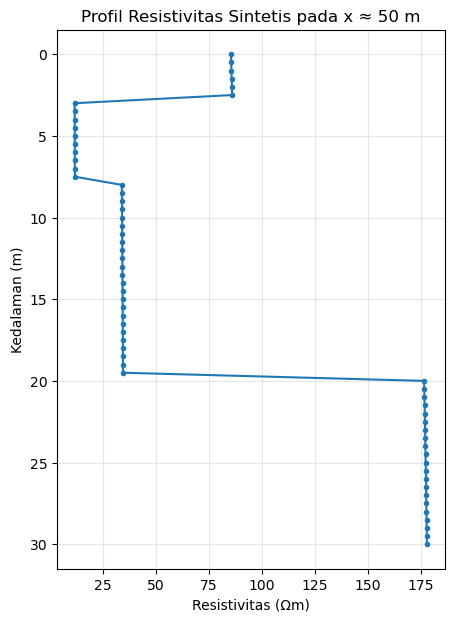

In [5]:
# Profil vertikal pada posisi x terdekat dengan 50 m
ix = np.argmin(np.abs(x - 50))
fig, ax = plt.subplots(figsize=(5, 7))
ax.plot(rho[:, ix], z, marker="o", ms=3)
ax.invert_yaxis()
ax.set_xlabel("Resistivitas (Ωm)")
ax.set_ylabel("Kedalaman (m)")
ax.set_title("Profil Resistivitas Sintetis pada x ≈ 50 m")
ax.grid(True, alpha=0.3)
plt.show()

## 4. Perkiraan zona potensial akuifer
Dalam model contoh, lapisan 3 berada pada kedalaman 8–20 m sehingga ketebalan geometrisnya adalah:

\[
b = z_{dasar} - z_{puncak} = 20 - 8 = 12\ \text{m}
\]

Angka ini hanya menjelaskan model sintetis. Ketebalan efektif akuifer dan produktivitasnya tidak dapat ditentukan dari resistivitas saja.

In [6]:
aquifer_top = 8
aquifer_base = 20
aquifer_thickness = aquifer_base - aquifer_top
print(f"Kedalaman atas zona potensial (model sintetis): {aquifer_top} m")
print(f"Kedalaman bawah zona potensial (model sintetis): {aquifer_base} m")
print(f"Ketebalan geometris (model sintetis): {aquifer_thickness} m")

Kedalaman atas zona potensial (model sintetis): 8 m
Kedalaman bawah zona potensial (model sintetis): 20 m
Ketebalan geometris (model sintetis): 12 m


## 5. Tahapan untuk data lapangan
1. Periksa data arus, beda potensial, konfigurasi, jarak elektroda, koordinat, dan satuan.
2. Hitung resistivitas semu menggunakan faktor geometri konfigurasi yang benar.
3. Lakukan kontrol kualitas dan pemeriksaan data menyimpang.
4. Jalankan inversi 1D/2D/3D sesuai desain survei (misalnya dengan RES2DINV atau pyGIMLi).
5. Evaluasi misfit/RMS dan kewajaran model; jangan menilai kualitas hanya dari RMS.
6. Tafsirkan model bersama peta geologi, data sumur, muka air tanah, dan uji pemompaan.

## 6. Kesimpulan
Model sintetis menunjukkan satu lapisan yang *secara hipotetis* dapat mewakili akuifer pada kedalaman 8–20 m dengan ketebalan geometris 12 m. Ini bukan hasil survei aktual. Konfirmasi memerlukan data lapangan, inversi, kontrol geologi, dan idealnya pengeboran serta uji hidraulik.

# Prompt 2 — Geomagnetik: Identifikasi Struktur Geologi

**Nama:** Abdussalam Said Al Mubarak  
**NIM:** H061241027

Notebook ini menggunakan data magnetik sintetis untuk memperlihatkan koreksi variasi harian sederhana, pemisahan komponen regional-residual ilustratif, dan peta anomali. Nilai bukan data observasi lapangan. Interpretasi anomali magnetik tidak unik: anomali dapat disebabkan oleh kontras suseptibilitas, geometri, kedalaman, remanensi, atau noise.

## 1. Alur pengolahan
Data medan magnet observasi → koreksi variasi harian (bila base station tersedia) → koreksi/rujukan IGRF untuk memperoleh anomali medan total → pemeriksaan tren regional → interpretasi geologi. Koreksi harus mengikuti metadata instrumen, waktu, dan prosedur survei yang sebenarnya.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(7)

## 2. Membuat data magnetik sintetis
Contoh ini membuat grid koordinat dan anomali sintetis dengan satu anomali positif dan satu negatif. Komponen regional, variasi harian, dan noise ditambahkan untuk demonstrasi.

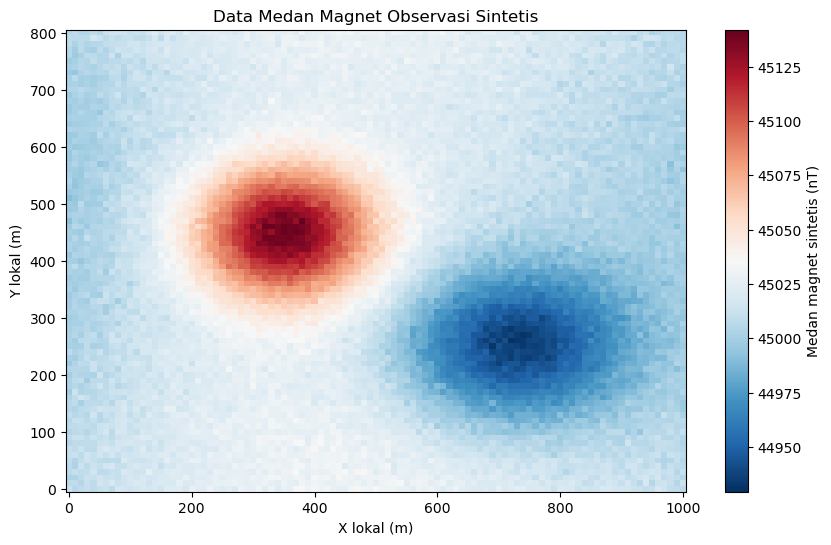

In [8]:
x = np.linspace(0, 1000, 101)  # m
y = np.linspace(0, 800, 81)     # m
X, Y = np.meshgrid(x, y)

regional = 0.015*X + 0.008*Y
anom_pos = 120*np.exp(-(((X-350)/150)**2 + ((Y-450)/120)**2))
anom_neg = -85*np.exp(-(((X-720)/190)**2 + ((Y-250)/140)**2))
true_anomaly = anom_pos + anom_neg
diurnal = 18*np.sin(X/260) + 7*np.cos(Y/180)
noise = np.random.normal(0, 3, size=X.shape)
observed_synthetic = 45000 + regional + true_anomaly + diurnal + noise

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.pcolormesh(X, Y, observed_synthetic, shading="auto", cmap="RdBu_r")
fig.colorbar(im, ax=ax, label="Medan magnet sintetis (nT)")
ax.set_xlabel("X lokal (m)"); ax.set_ylabel("Y lokal (m)")
ax.set_title("Data Medan Magnet Observasi Sintetis")
plt.show()

## 3. Koreksi variasi harian
Pada survei nyata, variasi harian biasanya dikoreksi menggunakan rekaman base station yang tersinkronisasi waktu. Karena notebook ini tidak memiliki data base station, fungsi di bawah memakai sinyal harian sintetis yang diketahui hanya untuk demonstrasi. **Jangan mengganti data base station nyata dengan fungsi ini untuk laporan survei.**

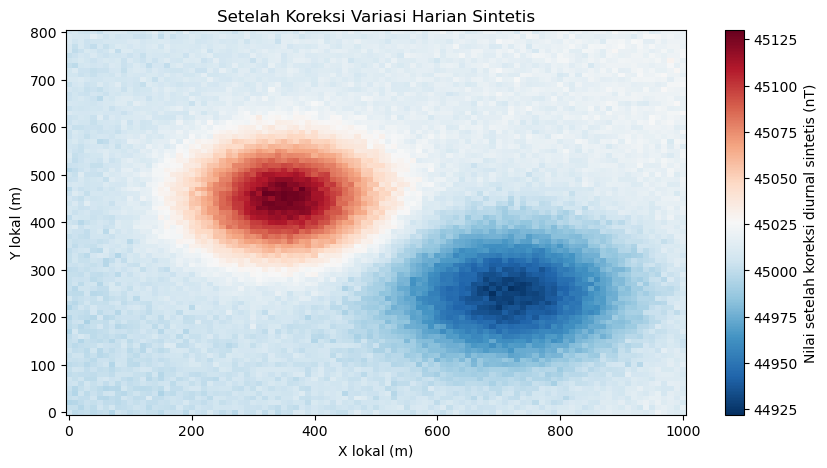

In [9]:
# Demonstrasi: komponen diurnal sintetis dianggap diketahui
corrected_for_diurnal = observed_synthetic - diurnal

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.pcolormesh(X, Y, corrected_for_diurnal, shading="auto", cmap="RdBu_r")
fig.colorbar(im, ax=ax, label="Nilai setelah koreksi diurnal sintetis (nT)")
ax.set_xlabel("X lokal (m)"); ax.set_ylabel("Y lokal (m)")
ax.set_title("Setelah Koreksi Variasi Harian Sintetis")
plt.show()

## 4. Pemisahan regional dan residual ilustratif
Dalam contoh ini, komponen regional yang dibangkitkan sebelumnya diketahui sehingga dapat dikurangkan secara langsung. Pada data nyata, pemisahan regional-residual membutuhkan metode yang dijelaskan dengan jelas (misalnya tren polinomial atau filter) dan hasilnya bergantung pada skala struktur yang ingin diteliti.

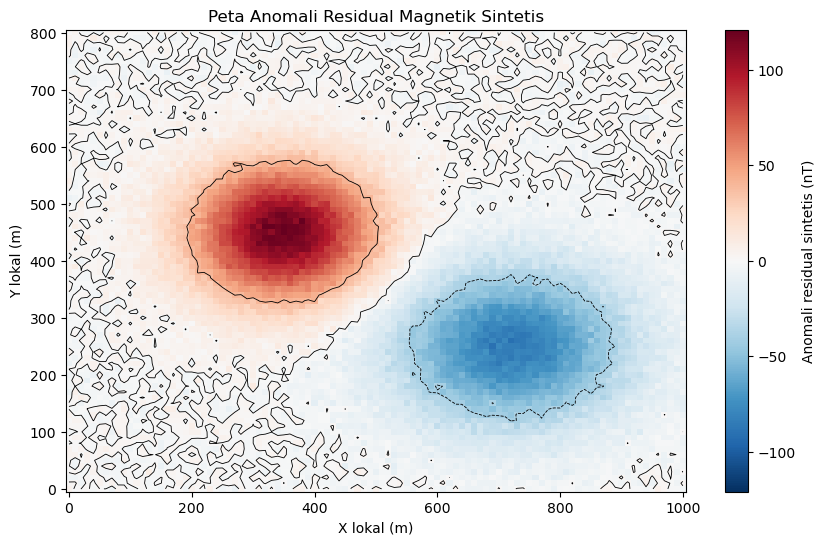

In [10]:
residual_synthetic = corrected_for_diurnal - 45000 - regional

fig, ax = plt.subplots(figsize=(10, 6))
lim = np.nanmax(np.abs(residual_synthetic))
im = ax.pcolormesh(X, Y, residual_synthetic, shading="auto",
                   cmap="RdBu_r", vmin=-lim, vmax=lim)
fig.colorbar(im, ax=ax, label="Anomali residual sintetis (nT)")
ax.contour(X, Y, residual_synthetic, levels=[-40, 0, 40], colors="k", linewidths=0.6)
ax.set_xlabel("X lokal (m)"); ax.set_ylabel("Y lokal (m)")
ax.set_title("Peta Anomali Residual Magnetik Sintetis")
plt.show()

## 5. Identifikasi zona anomali
Zona positif dan negatif pada peta adalah fitur sintetis yang sengaja dibuat. Tanda anomali tidak langsung mengidentifikasi litologi atau struktur tertentu.

In [11]:
print("Rentang anomali residual sintetis:",
      f"{residual_synthetic.min():.1f} hingga {residual_synthetic.max():.1f} nT")
print("Puncak positif sintetis pada sekitar:",
      int(X[np.unravel_index(np.argmax(residual_synthetic), residual_synthetic.shape)]), "m X,",
      int(Y[np.unravel_index(np.argmax(residual_synthetic), residual_synthetic.shape)]), "m Y")
print("Puncak negatif sintetis pada sekitar:",
      int(X[np.unravel_index(np.argmin(residual_synthetic), residual_synthetic.shape)]), "m X,",
      int(Y[np.unravel_index(np.argmin(residual_synthetic), residual_synthetic.shape)]), "m Y")

Rentang anomali residual sintetis: -90.9 hingga 120.9 nT
Puncak positif sintetis pada sekitar: 320 m X, 460 m Y
Puncak negatif sintetis pada sekitar: 720 m X, 260 m Y


## 6. Interpretasi dan ketidakpastian
- Anomali positif dapat berhubungan dengan batuan bermagnetisasi lebih kuat atau geometri sumber tertentu.
- Anomali negatif dapat berhubungan dengan kontras magnetisasi, arah magnetisasi, atau efek geometri.
- Zona gradien tinggi dapat membantu menandai kontak litologi atau struktur, tetapi bukan bukti tunggal sesar.
- Intrusi hanya dapat dipertimbangkan bila pola anomali konsisten dengan geologi regional dan data pendukung.
- Kedalaman dan bentuk sumber tidak dapat ditentukan unik dari peta anomali saja.

## 7. Checklist data lapangan
1. Periksa koordinat, waktu, satuan, kalibrasi, dan drift instrumen.
2. Terapkan koreksi base station berdasarkan waktu.
3. Terapkan koreksi IGRF yang sesuai dengan lokasi, tanggal, dan elevasi.
4. Periksa apakah data sudah berupa medan total atau anomali.
5. Dokumentasikan metode pemisahan regional-residual.
6. Bandingkan dengan peta geologi dan metode geofisika lain.

## 8. Kesimpulan
Peta yang ditampilkan merupakan demonstrasi alur pemrosesan data magnetik sintetis. Tidak ada sesar, kontak batuan, atau intrusi nyata yang dapat disimpulkan sebelum data survei aktual dan konteks geologi tersedia.

# Prompt 3 — Seismik Refraksi: Menentukan Kedalaman Batuan Dasar

**Nama:** Abdussalam Said Al Mubarak  
**NIM:** H061241027

Notebook ini mendemonstrasikan picking first arrival sintetis, kurva travel-time, estimasi kecepatan, dan model dua lapisan horizontal dengan metode waktu intersep. Model ini mengasumsikan kecepatan meningkat terhadap kedalaman dan lapisan relatif horizontal; data nyata dapat melanggar asumsi tersebut.

## 1. Prinsip metode
Gelombang P direkam pada geophone dengan jarak yang diketahui. Grafik waktu tiba pertama terhadap jarak digunakan untuk mengenali kemiringan segmen yang berkaitan dengan kecepatan semu. Untuk model dua lapisan horizontal dengan V2 > V1, kedalaman antarmuka dapat diestimasi dari kecepatan lapisan dan waktu intersep.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(21)

## 2. Membuat data first-arrival sintetis
Model demonstrasi menggunakan lapisan atas dengan V1 = 500 m/s dan lapisan bawah dengan V2 = 1800 m/s. Nilai tersebut hanya parameter sintetis, bukan identifikasi jenis batuan.

In [13]:
v1_true = 500.0   # m/s
v2_true = 1800.0  # m/s
h_true = 8.0      # m
x = np.arange(5, 101, 5, dtype=float)

critical_angle = np.arcsin(v1_true / v2_true)
t_intercept = 2*h_true*np.cos(critical_angle)/v2_true
t_direct = x / v1_true
t_head = t_intercept + x / v2_true
t_first_true = np.minimum(t_direct, t_head)
t_observed = t_first_true + np.random.normal(0, 0.0015, size=x.size)

data = pd.DataFrame({"Jarak geophone (m)": x,
                     "First arrival sintetis (s)": t_observed})
display(data.head())

,Jarak geophone (m),First arrival sintetis (s)
0,5.0,0.009922
1,10.0,0.013928
2,15.0,0.018435
3,20.0,0.017765
4,25.0,0.023546


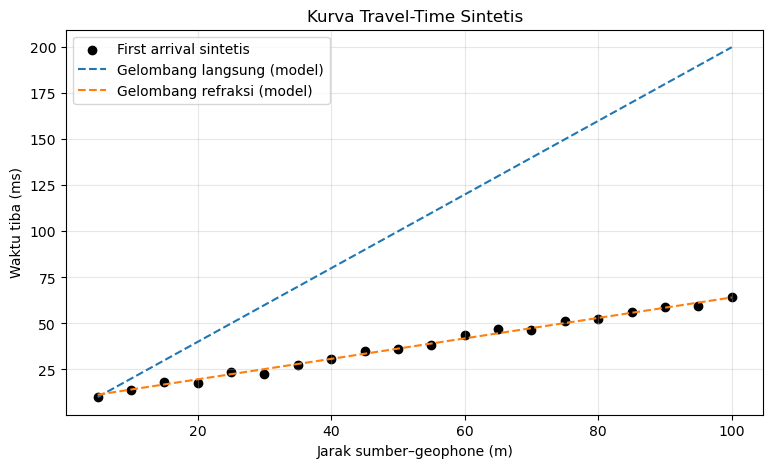

In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(x, t_observed*1000, label="First arrival sintetis", color="black")
ax.plot(x, t_direct*1000, "--", label="Gelombang langsung (model)")
ax.plot(x, t_head*1000, "--", label="Gelombang refraksi (model)")
ax.set_xlabel("Jarak sumber–geophone (m)")
ax.set_ylabel("Waktu tiba (ms)")
ax.set_title("Kurva Travel-Time Sintetis")
ax.grid(True, alpha=0.3); ax.legend()
plt.show()

## 3. Estimasi kecepatan dari segmen travel-time
Kecepatan dihitung sebagai kebalikan kemiringan waktu terhadap jarak. Pada data nyata, segmen harus dipilih berdasarkan first arrival dan interpretasi cabang travel-time, bukan semata-mata berdasarkan pembagian rentang jarak secara otomatis.

In [15]:
# Untuk demonstrasi, gunakan rentang dekat untuk gelombang langsung dan rentang jauh untuk refraksi
near = x <= 15
far = x >= 50

slope1, intercept1 = np.polyfit(x[near], t_observed[near], 1)
slope2, intercept2 = np.polyfit(x[far], t_observed[far], 1)
v1_est = 1/slope1
v2_est = 1/slope2
ti_est = intercept2

print(f"Estimasi V1 dari cabang dekat: {v1_est:.1f} m/s")
print(f"Estimasi V2 dari cabang jauh: {v2_est:.1f} m/s")
print(f"Waktu intersep estimasi: {ti_est*1000:.2f} ms")

Estimasi V1 dari cabang dekat: 1174.7 m/s
Estimasi V2 dari cabang jauh: 1876.2 m/s
Waktu intersep estimasi: 10.38 ms


## 4. Estimasi kedalaman antarmuka dua lapisan
Untuk model dua lapisan horizontal:

$$
t_i = \frac{2h\cos i_c}{V_2},\qquad
\sin i_c = \frac{V_1}{V_2}
$$

sehingga:

$$
h = \frac{t_i V_2}{2\cos i_c}
$$

Persamaan hanya sesuai bila asumsi model dua lapisan terpenuhi dan V2 > V1.

In [16]:
if v2_est > v1_est and ti_est > 0:
    ic_est = np.arcsin(np.clip(v1_est/v2_est, -1, 1))
    h_est = ti_est*v2_est/(2*np.cos(ic_est))
    print(f"Sudut kritis estimasi: {np.degrees(ic_est):.2f}°")
    print(f"Kedalaman antarmuka estimasi: {h_est:.2f} m")
else:
    h_est = np.nan
    print("Kedalaman tidak dapat dihitung dengan asumsi model dua lapisan dari estimasi ini.")

Sudut kritis estimasi: 38.76°
Kedalaman antarmuka estimasi: 12.49 m


## 5. Penampang model bawah permukaan
Penampang ini menggunakan parameter estimasi dari data sintetis. Warna menunjukkan lapisan dengan kecepatan berbeda, bukan identifikasi litologi definitif.

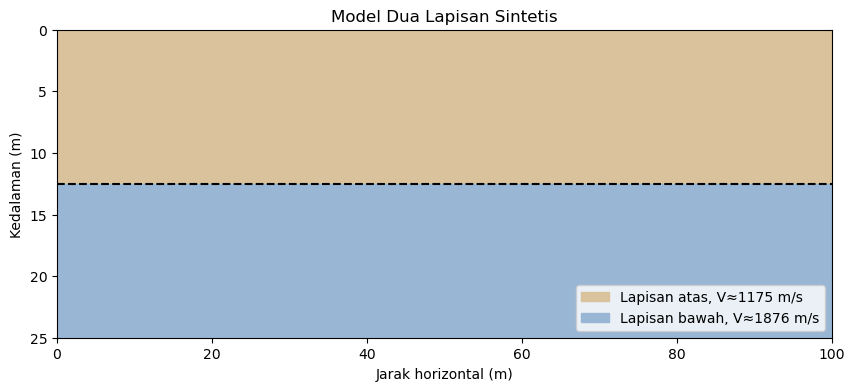

In [17]:
fig, ax = plt.subplots(figsize=(10, 4))
depth_plot = h_est if np.isfinite(h_est) else h_true
ax.fill_between([0, 100], [0, 0], [depth_plot, depth_plot],
                color="#d9c29c", label=f"Lapisan atas, V≈{v1_est:.0f} m/s")
ax.fill_between([0, 100], [depth_plot, depth_plot], [25, 25],
                color="#9ab6d5", label=f"Lapisan bawah, V≈{v2_est:.0f} m/s")
ax.axhline(depth_plot, color="k", ls="--")
ax.set_xlim(0, 100); ax.set_ylim(25, 0)
ax.set_xlabel("Jarak horizontal (m)"); ax.set_ylabel("Kedalaman (m)")
ax.set_title("Model Dua Lapisan Sintetis")
ax.legend(loc="lower right")
plt.show()

## 6. Interpretasi dan keterbatasan
- Kecepatan rendah pada lapisan dangkal dapat berkaitan dengan tanah lepas, material lapuk, atau sedimen tidak terkonsolidasi.
- Kecepatan lebih tinggi dapat menunjukkan material lebih kompak atau batuan, tetapi rentang kecepatan antarjenis material saling tumpang tindih.
- Lapisan berkecepatan rendah di bawah lapisan berkecepatan tinggi dapat tidak terdeteksi dengan baik oleh refraksi konvensional (hidden layer).
- Topografi, variasi lateral, anisotropi, dan picking yang tidak konsisten dapat memengaruhi hasil.
- Penentuan batuan dasar perlu dikombinasikan dengan geologi, bor, atau metode geofisika lain.

## 7. Kesimpulan
Notebook menghasilkan kurva travel-time dan estimasi ilustratif untuk model dua lapisan. Kedalaman yang dihitung hanya berlaku bagi data sintetis dan asumsi lapisan horizontal. Untuk survei nyata, gunakan first arrival aktual, dokumentasikan picking, evaluasi kualitas regresi, dan uji kecocokan model geologi.

# Prompt 4 — GPR: Deteksi Utilitas Bawah Tanah

**Nama:** Abdussalam Said Al Mubarak  
**NIM:** H061241027

Notebook ini membuat radargram sintetis dengan refleksi horizontal, gelombang langsung, noise, dan satu respons hiperbola yang menyerupai objek titik. Notebook memperlihatkan preprocessing dasar. Radargram sintetis tidak menunjukkan utilitas nyata; estimasi kedalaman bergantung pada kecepatan elektromagnetik yang harus dikalibrasi untuk kondisi tanah setempat.

## 1. Prinsip dan alur preprocessing
Tahapan yang umum digunakan meliputi pemeriksaan data, time-zero correction, dewow, background removal, gain, dan filtering sesuai kebutuhan. Pemrosesan harus menjaga agar refleksi yang relevan tidak ikut terhapus.

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

np.random.seed(10)

## 2. Membuat radargram sintetis
Sumbu vertikal adalah two-way travel time (ns), sedangkan sumbu horizontal adalah jarak lintasan (m).

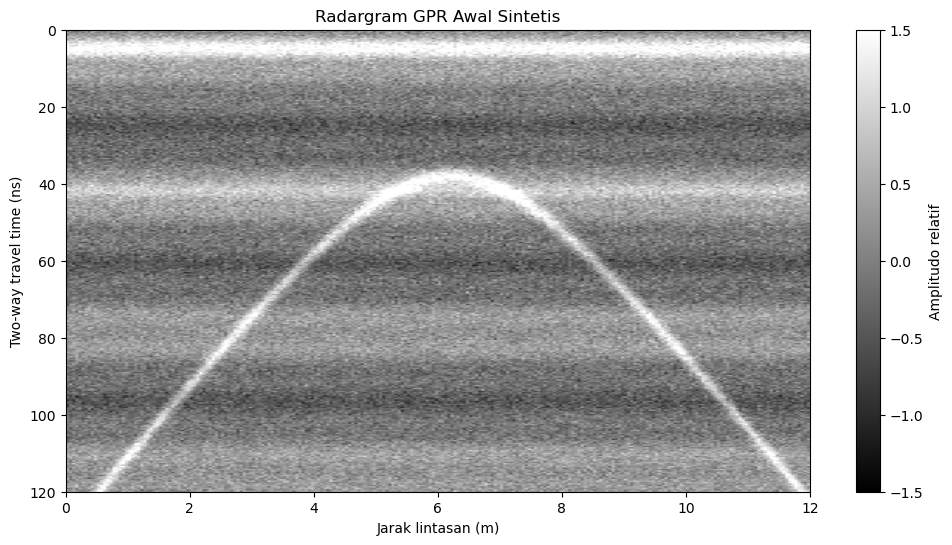

In [19]:
nx, nt = 240, 320
x = np.linspace(0, 12, nx)
t_ns = np.linspace(0, 120, nt)
T, X = np.meshgrid(t_ns, x, indexing="ij")

# Background banding dan noise
background = 0.35*np.sin(2*np.pi*T/35) + 0.12*np.sin(2*np.pi*T/9)
direct_wave = 1.4*np.exp(-((T-5)/2.5)**2)
layer_reflection = 0.7*np.exp(-((T-42)/2.2)**2) * np.ones_like(X)

# Hiperbola sintetis dari objek titik pada x0, waktu puncak t0
x0, t0 = 6.2, 38.0
v_m_per_ns = 0.10  # ilustratif, setara 0.10 m/ns
hyperbola_time = np.sqrt(t0**2 + (2*(X-x0)/v_m_per_ns)**2)
hyperbola = 1.2*np.exp(-((T-hyperbola_time)/2.0)**2)

raw = background + direct_wave + layer_reflection + hyperbola + np.random.normal(0, 0.22, (nt, nx))

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(raw, extent=[x.min(), x.max(), t_ns.max(), t_ns.min()],
               aspect="auto", cmap="gray", vmin=-1.5, vmax=1.5)
fig.colorbar(im, ax=ax, label="Amplitudo relatif")
ax.set_xlabel("Jarak lintasan (m)"); ax.set_ylabel("Two-way travel time (ns)")
ax.set_title("Radargram GPR Awal Sintetis")
plt.show()

## 3. Preprocessing: dewow dan background removal
Dewow di sini dilakukan dengan mengurangi tren lokal sepanjang sumbu waktu. Background removal dilakukan dengan mengurangi rata-rata tiap sampel waktu di sepanjang lintasan. Parameter perlu disesuaikan dengan data aktual karena proses ini dapat menghilangkan reflektor yang menerus.

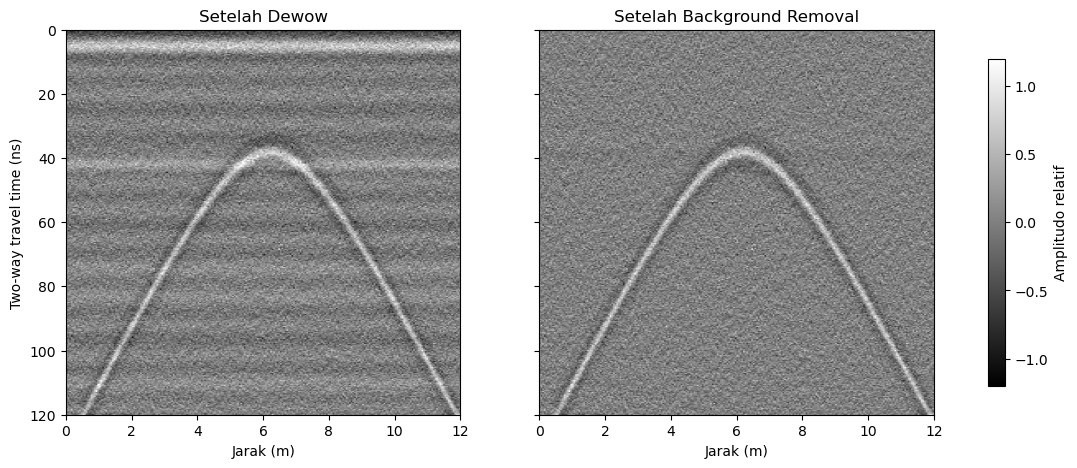

In [20]:
# Dewow: kurangi komponen lambat sepanjang sumbu waktu
dewowed = raw - gaussian_filter1d(raw, sigma=8, axis=0)

# Background removal: kurangi rata-rata lateral pada tiap waktu
background_removed = dewowed - np.mean(dewowed, axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, arr, title in zip(axes, [dewowed, background_removed],
                          ["Setelah Dewow", "Setelah Background Removal"]):
    im = ax.imshow(arr, extent=[x.min(), x.max(), t_ns.max(), t_ns.min()],
                   aspect="auto", cmap="gray", vmin=-1.2, vmax=1.2)
    ax.set_title(title); ax.set_xlabel("Jarak (m)")
axes[0].set_ylabel("Two-way travel time (ns)")
fig.colorbar(im, ax=axes, label="Amplitudo relatif", shrink=0.85)
plt.show()

## 4. Gain dan radargram hasil pemrosesan
Gain sederhana ditambahkan agar refleksi yang lebih dalam lebih mudah terlihat. Gain juga dapat memperkuat noise sehingga harus digunakan dengan hati-hati.

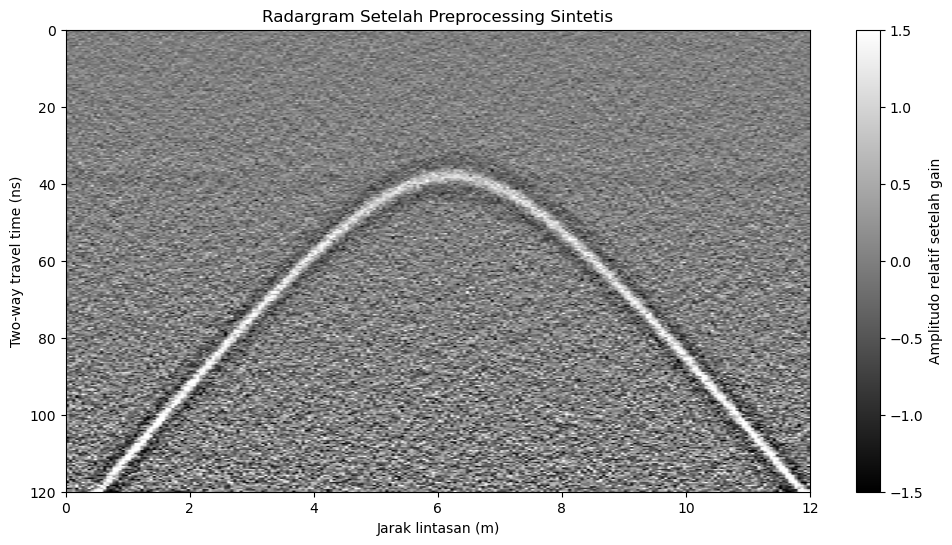

In [21]:
gain = 1 + (T/70)**1.5
processed = background_removed * gain

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(processed, extent=[x.min(), x.max(), t_ns.max(), t_ns.min()],
               aspect="auto", cmap="gray", vmin=-1.5, vmax=1.5)
fig.colorbar(im, ax=ax, label="Amplitudo relatif setelah gain")
ax.set_xlabel("Jarak lintasan (m)"); ax.set_ylabel("Two-way travel time (ns)")
ax.set_title("Radargram Setelah Preprocessing Sintetis")
plt.show()

## 5. Estimasi kedalaman reflektor
Untuk reflektor horizontal, perkiraan kedalaman dapat dihitung dengan:

\[
d = \frac{v t}{2}
\]

dengan `v` adalah kecepatan gelombang elektromagnetik dan `t` adalah two-way travel time dalam satuan yang konsisten. Untuk demonstrasi, gunakan v = 0.10 m/ns dan reflektor pada t = 42 ns.

In [22]:
velocity_m_per_ns = 0.10  # asumsi ilustratif; sebaiknya dikalibrasi
twtt_ns = 42.0
depth_m = velocity_m_per_ns * twtt_ns / 2
print(f"Kedalaman ilustratif reflektor: {depth_m:.2f} m")
print("Nilai ini bukan kedalaman utilitas terverifikasi.")

Kedalaman ilustratif reflektor: 2.10 m
Nilai ini bukan kedalaman utilitas terverifikasi.


## 6. Interpretasi pola hiperbola
Hiperbola dapat muncul dari objek terbatas seperti pipa, batu, akar, atau target titik lainnya. Bentuk hiperbola tidak cukup untuk menentukan jenis objek secara pasti. Estimasi kedalaman puncak hiperbola memerlukan kecepatan yang sesuai; kecepatan dapat diperkirakan melalui fitting hiperbola, CMP/WARR, atau kalibrasi dengan objek yang diketahui.

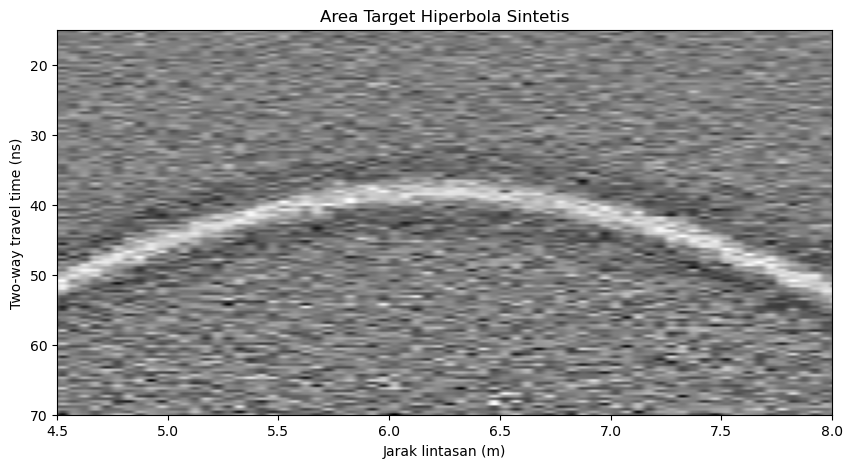

In [23]:
# Tampilan zoom area sekitar hiperbola pada radargram hasil preprocessing
fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(processed, extent=[x.min(), x.max(), t_ns.max(), t_ns.min()],
               aspect="auto", cmap="gray", vmin=-1.5, vmax=1.5)
ax.set_xlim(4.5, 8.0); ax.set_ylim(70, 15)
ax.set_xlabel("Jarak lintasan (m)"); ax.set_ylabel("Two-way travel time (ns)")
ax.set_title("Area Target Hiperbola Sintetis")
plt.show()

## 7. Peta posisi target
Untuk survei nyata, posisi target harus dikaitkan dengan koordinat GNSS dan lintasan survei. Plot ini hanya menandai posisi target pada koordinat lintasan sintetis.

In [24]:
target_x = x0
target_twtt = t0
target_depth = velocity_m_per_ns * target_twtt / 2
print(f"Posisi lintasan sintetis: x ≈ {target_x:.2f} m")
print(f"Waktu puncak target sintetis: {target_twtt:.1f} ns")
print(f"Kedalaman puncak estimasi sintetis: {target_depth:.2f} m")

Posisi lintasan sintetis: x ≈ 6.20 m
Waktu puncak target sintetis: 38.0 ns
Kedalaman puncak estimasi sintetis: 1.90 m


## 8. Kesimpulan dan rekomendasi
Notebook memperlihatkan radargram awal, preprocessing, dan estimasi kedalaman ilustratif. Untuk utilitas aktual, gunakan data GPR mentah, dokumentasikan antena dan interval trace, lakukan time-zero correction, tentukan kecepatan dari kalibrasi yang sesuai, dan konfirmasi target dengan informasi utilitas atau survei tambahan sebelum penggalian.

# Prompt 5 — Gravitasi: Identifikasi Cekungan dan Struktur Bawah Permukaan

**Nama:** Abdussalam Said Al Mubarak  
**NIM:** H061241027

Notebook ini mendemonstrasikan koreksi gravitasi sederhana dan peta anomali menggunakan data sintetis. Data tidak mewakili survei aktual. Koreksi gravitasi yang benar membutuhkan metadata alat, waktu, koordinat, elevasi, datum, model densitas Bouguer, dan topografi yang sesuai.

## 1. Tahapan koreksi gravitasi
Secara umum, pengolahan dapat mencakup:
1. Pemeriksaan data dan satuan.
2. Koreksi pasang surut (tidal) bila belum diterapkan.
3. Koreksi drift instrumen berdasarkan pengukuran base station/loop.
4. Koreksi lintang atau normal gravity.
5. Koreksi free-air berdasarkan elevasi.
6. Koreksi Bouguer dengan asumsi densitas slab.
7. Koreksi terrain jika topografi signifikan.
8. Pemisahan regional-residual bila diperlukan dan dijelaskan.

Urutan dan tanda koreksi harus mengikuti konvensi data serta perangkat lunak yang digunakan. Contoh berikut bersifat pedagogis, bukan prosedur pengganti pemrosesan survei profesional.

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(15)

## 2. Membuat data gravitasi sintetis
Data contoh menggunakan grid koordinat, topografi sederhana, dan anomali yang merepresentasikan cekungan berdensitas relatif rendah serta tubuh berdensitas relatif tinggi.

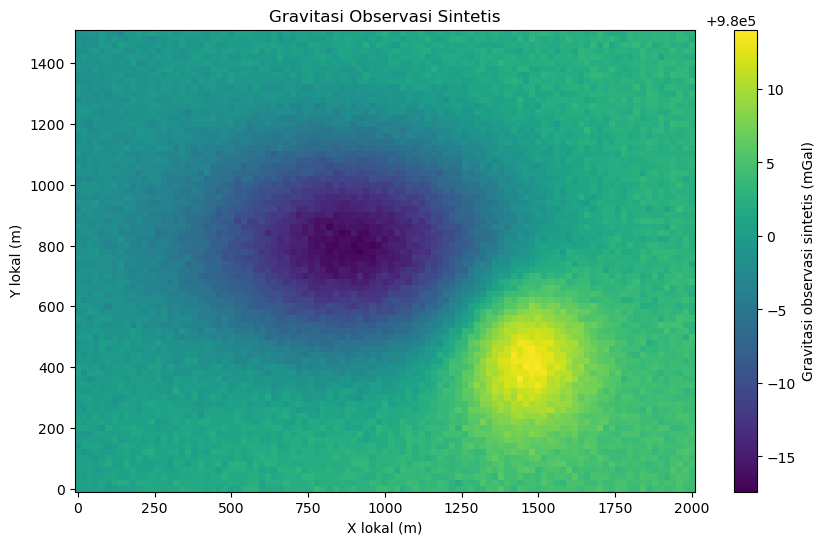

In [26]:
x = np.linspace(0, 2000, 101)  # m
y = np.linspace(0, 1500, 76)    # m
X, Y = np.meshgrid(x, y)

elevation = 100 + 20*np.sin(X/500)*np.cos(Y/450)  # m, topografi sintetis
basin = -18*np.exp(-(((X-900)/500)**2 + ((Y-800)/350)**2))
dense_body = 12*np.exp(-(((X-1450)/220)**2 + ((Y-450)/250)**2))
regional = 0.002*X - 0.001*Y
residual_true = basin + dense_body
noise = np.random.normal(0, 0.5, X.shape)

# Komponen observasi sintetis (mGal), dibuat sederhana untuk demonstrasi
g_reference = 980000.0
drift = 0.8*np.sin(X/700)
tidal = 0.4*np.cos(Y/300)
g_observed = g_reference + regional + residual_true + drift + tidal + noise

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.pcolormesh(X, Y, g_observed, shading="auto", cmap="viridis")
fig.colorbar(im, ax=ax, label="Gravitasi observasi sintetis (mGal)")
ax.set_xlabel("X lokal (m)"); ax.set_ylabel("Y lokal (m)")
ax.set_title("Gravitasi Observasi Sintetis")
plt.show()

## 3. Tabel contoh dan komponen koreksi
Tabel di bawah menampilkan satu titik contoh. Koreksi drift dan tidal diketahui karena dibuat sintetis. Pada survei nyata, drift ditentukan dari pengukuran berulang/base station dan tidal dihitung atau diambil dari model sesuai waktu pengukuran.

In [27]:
iy, ix = 30, 50
example = pd.DataFrame([{
    "X (m)": X[iy, ix], "Y (m)": Y[iy, ix],
    "Elevasi (m)": elevation[iy, ix],
    "Gravitasi observasi sintetis (mGal)": g_observed[iy, ix],
    "Koreksi drift demonstrasi (mGal)": -drift[iy, ix],
    "Koreksi tidal demonstrasi (mGal)": -tidal[iy, ix],
    "Setelah koreksi drift & tidal (mGal)": g_observed[iy, ix]-drift[iy, ix]-tidal[iy, ix]
}])
display(example)

,X (m),Y (m),Elevasi (m),Gravitasi observasi sintetis (mGal),Koreksi drift demonstrasi (mGal),Koreksi tidal demonstrasi (mGal),Setelah koreksi drift & tidal (mGal)
0,1000.0,600.0,104.278018,979990.139101,-0.791922,0.166459,979989.513637


## 4. Free-air dan Bouguer sederhana
Untuk ilustrasi digunakan pendekatan:
- Free-air correction ≈ `0.3086 mGal/m × elevasi (m)`.
- Bouguer slab correction ≈ `0.04193 × densitas (g/cm³) × elevasi (m)` dalam mGal.

Nilai densitas Bouguer harus dipilih berdasarkan kondisi geologi atau analisis yang sesuai. Rumus ini belum mencakup semua detail datum, topografi, maupun konvensi koreksi.

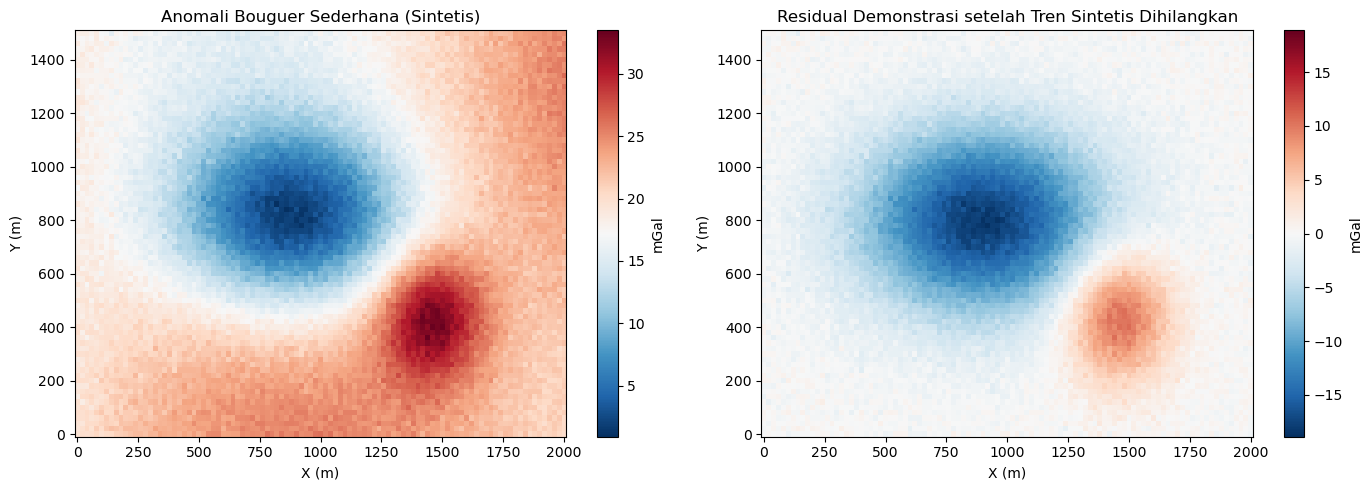

In [28]:
rho_bouguer = 2.67  # g/cm^3, asumsi ilustratif
free_air_corr = 0.3086 * elevation
bouguer_slab_corr = 0.04193 * rho_bouguer * elevation

# Anomali Bouguer sederhana: setelah drift/tidal, tambah free-air, kurangi slab Bouguer,
# lalu kurangi nilai gravitasi referensi dan tren regional sintetis untuk visualisasi residual.
g_dt_corrected = g_observed - drift - tidal
simple_bouguer_anomaly = g_dt_corrected - g_reference + free_air_corr - bouguer_slab_corr

# Untuk peta residual demonstrasi, komponen regional sintetis juga dihilangkan.
residual_demo = simple_bouguer_anomaly - regional - (free_air_corr - bouguer_slab_corr)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
im1 = axes[0].pcolormesh(X, Y, simple_bouguer_anomaly, shading="auto", cmap="RdBu_r")
axes[0].set_title("Anomali Bouguer Sederhana (Sintetis)")
axes[0].set_xlabel("X (m)"); axes[0].set_ylabel("Y (m)")
fig.colorbar(im1, ax=axes[0], label="mGal")
lim = np.max(np.abs(residual_demo))
im2 = axes[1].pcolormesh(X, Y, residual_demo, shading="auto", cmap="RdBu_r", vmin=-lim, vmax=lim)
axes[1].set_title("Residual Demonstrasi setelah Tren Sintetis Dihilangkan")
axes[1].set_xlabel("X (m)"); axes[1].set_ylabel("Y (m)")
fig.colorbar(im2, ax=axes[1], label="mGal")
plt.tight_layout()
plt.show()

## 5. Interpretasi anomali
Dalam model sintetis:
- Anomali negatif dapat konsisten dengan massa berdensitas lebih rendah atau cekungan berisi sedimen, tetapi juga dapat dipengaruhi kedalaman, geometri, dan regional.
- Anomali positif dapat konsisten dengan material berdensitas lebih tinggi atau tubuh batuan kompak, tetapi bukan bukti tunggal intrusi.
- Gravitasi memiliki ambiguitas: kombinasi densitas, ukuran, bentuk, dan kedalaman yang berbeda dapat menghasilkan anomali serupa.

Peta di bawah hanya memvisualisasikan anomali residual yang dibuat dalam simulasi.

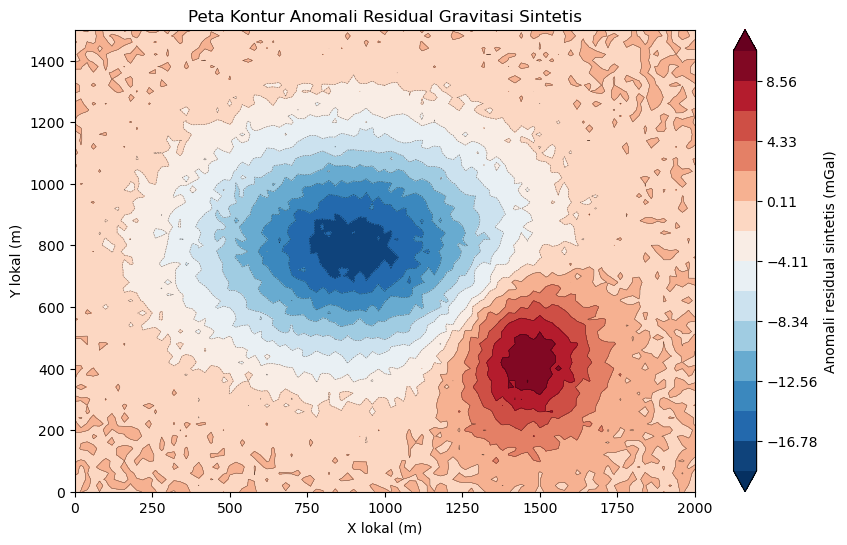

In [29]:
fig, ax = plt.subplots(figsize=(10, 6))
levels = np.linspace(np.nanmin(residual_demo), np.nanmax(residual_demo), 15)
cf = ax.contourf(X, Y, residual_demo, levels=levels, cmap="RdBu_r", extend="both")
ax.contour(X, Y, residual_demo, levels=levels, colors="k", linewidths=0.35, alpha=0.6)
fig.colorbar(cf, ax=ax, label="Anomali residual sintetis (mGal)")
ax.set_xlabel("X lokal (m)"); ax.set_ylabel("Y lokal (m)")
ax.set_title("Peta Kontur Anomali Residual Gravitasi Sintetis")
plt.show()

## 6. Keterbatasan dan kebutuhan data
- Koreksi terrain memerlukan topografi resolusi memadai dan jarak terhadap stasiun.
- Koreksi Bouguer sensitif terhadap asumsi densitas.
- Pemisahan regional-residual dapat mengubah bentuk anomali dan perlu justifikasi.
- Interpretasi cekungan, basement, atau intrusi sebaiknya didukung peta geologi, data sumur, seismik, magnetik, atau informasi densitas.
- Untuk pemodelan kuantitatif, tetapkan geometri sumber dan densitas, lalu lakukan forward modelling dan/atau inversi dengan regularisasi serta analisis ketidakpastian.

## 7. Kesimpulan
Notebook memperlihatkan contoh alur koreksi sederhana dan visualisasi anomali gravitasi sintetis. Nilai yang ditampilkan bukan hasil survei nyata dan tidak dapat digunakan untuk menyimpulkan keberadaan cekungan, basement, atau intrusi di lokasi tertentu tanpa data lapangan serta informasi geologi pendukung.